<a href="https://colab.research.google.com/github/crucueiv/Satellite-Orbit-Explorer/blob/main/SCW26Challenge3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

We are building this educational satellite orbit exploration simulator in 8 modular stages:
1. **Setup**: Import modules, set physical constants, and define workspace directories.
2. **Load GP JSON**: Extract inputs and parse Keplerian General Perturbations data.
3. **Parse Elements**: Convert mean motion and degrees to orbital components in SI metric units.
4. **Time Window**: Select a global UTC simulation time window based on dataset metadata.
5. **Propagate**: Solve Kepler's Equation to compute state vectors ($r$, $v$) over time.
6. **Orbit Summary**: Calculate perigee, apogee, period, and classification.
7. **Plots**: Generate 2D ground track visualizations and detailed telemetry subplots.
8. **KML and Report**: Export 3D trajectories to Google Earth KML files and generate a text report.

In [18]:
# Stage 1: Setup
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests
from IPython.display import display, Math

# Geocentric gravitational constant (km^3/s^2) and Earth equatorial radius (km)
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# Setup workspace directories inside /content/satellite_orbits
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Configuration settings
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None

# Verify setup and output using LaTeX representation
display(Math(r"\text{=== Stage 1 Setup Success ===}"))
display(Math(rf"\text{{Input Dir: }} \texttt{{{IN_DIR}}}"))
display(Math(rf"\text{{Output Dir: }} \texttt{{{OUT_DIR}}}"))
display(Math(rf"\Delta t = {STEP_SECONDS}\,\text{{s}},\quad T = {DURATION_HOURS}\,\text{{hours}},\quad \text{{Live Group}} = \text{{{LIVE_GROUP}}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Stage 2: Load GP JSON

OMM JSON (Orbit Mean-Elements Message in JSON format) is significantly easier to parse than the classic 3-line TLE (Two-Line Element set) format because it uses standard named key-value pairs instead of rigid column-based string offsets. Additionally, it natively supports clean ISO-8601 UTC date-time formats for the epoch and directly accommodates newer, six-digit catalog numbers without complex encoding schemes.

In [19]:
# Stage 2 Implementation: Input Extraction and GP JSON Loading

def extract_inputs():
    """Extract required files from upload zip or wait for upload."""
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).is_file() for f in required_files)

    if all_exist:
        print("Required input files already present in IN_DIR.")
        return

    # Wait for the zip file to be uploaded to /content
    target_dir = Path('/content')
    zip_path = None

    print("--- Action Required ---")
    print("Please drag and drop 'orbit_workshop_inputs.zip' into the Colab Files panel (under /content).")
    print("Waiting for upload...")

    start_time = time.time()
    timeout = 15 * 60  # 15 minutes

    while True:
        # Look for files matching 'orbit_workshop_inputs*.zip'
        matches = list(target_dir.glob('orbit_workshop_inputs*.zip'))
        if matches:
            candidate = matches[0]
            if zipfile.is_zipfile(candidate):
                zip_path = candidate
                break

        if time.time() - start_time > timeout:
            raise TimeoutError("Upload timeout reached. Please upload 'orbit_workshop_inputs.zip' to continue.")

        time.sleep(2)

    print(f"Found valid zip file: {zip_path.name}. Extracting required workspace files...")

    # Extract only the three specified files directly into IN_DIR
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for member in zip_ref.namelist():
            filename = Path(member).name
            if filename in required_files:
                target_path = IN_DIR / filename
                with zip_ref.open(member) as source_f, open(target_path, 'wb') as target_f:
                    target_f.write(source_f.read())
                print(f" Extracted: {filename} -> {target_path}")

def read_gp_json(path):
    """Load and validate OMM JSON data for orbital elements."""
    required_keys = {
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    }

    with open(path, 'r') as f:
        data = json.load(f)

    validated_sats = []
    for i, record in enumerate(data):
        missing = required_keys - record.keys()
        if missing:
            raise ValueError(f"Record at index {i} is missing required elements: {missing}")
        validated_sats.append(record)

    return validated_sats

# Run the tasks
extract_inputs()

# Read satellite data and manifest
sats = read_gp_json(IN_DIR / 'orbital_elements.json')
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

# Build and print a one-line source description
source_note = f"Source: {data_manifest.get('source', 'Unknown')} (Retrieved: {data_manifest.get('retrieved_utc', 'N/A')})"
print(f"\n{source_note}")
print(f"Loaded {len(sats)} satellites:")
for sat in sats:
    print(f" - Name: {sat['OBJECT_NAME']:<20} | NORAD ID: {sat['NORAD_CAT_ID']:<6} | Epoch: {sat['EPOCH']}")

Required input files already present in IN_DIR.

Source: Unknown (Retrieved: 2026-11-10T16:30:32Z)
Loaded 4 satellites:
 - Name: PULSAR-0             | NORAD ID: 64541  | Epoch: 2026-11-10T04:10:34.900320
 - Name: GSAT0225 (GALILEO 29) | NORAD ID: 59598  | Epoch: 2026-11-09T08:30:06.579648
 - Name: SES-5                | NORAD ID: 38652  | Epoch: 2026-11-10T04:02:09.139776
 - Name: QZS-2 (MICHIBIKI-2)  | NORAD ID: 42738  | Epoch: 2026-10-17T15:21:52.982784


In [20]:
if LIVE_GROUP:
    live_file = IN_DIR / f'gp_{LIVE_GROUP}.json'
    # Cache elements for at most 2 hours to prevent aggressive polling
    if not live_file.exists() or (time.time() - live_file.stat().st_mtime > 2 * 3600):
        url = f'https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON'
        print(f"Downloading live orbital data from: {url}")
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        # Validate JSON content before writing
        data_json = response.json()
        if not isinstance(data_json, list):
            raise ValueError("Unexpected format returned from CelesTrak API.")
        live_file.write_text(json.dumps(data_json), encoding='utf-8')

    retrieved = datetime.fromtimestamp(live_file.stat().st_mtime, timezone.utc)
    sats = sorted(read_gp_json(live_file), key=lambda s: int(s['NORAD_CAT_ID']))[:4]
    source_note = f"Live CelesTrak GP JSON, group {LIVE_GROUP}, retrieved {retrieved:%Y-%m-%d %H:%M} UTC"
    print(source_note)
    print(f"Selected {len(sats)} live satellites:")
    for sat in sats:
        print(f" - Name: {sat['OBJECT_NAME']:<20} | NORAD ID: {sat['NORAD_CAT_ID']:<6} | Epoch: {sat['EPOCH']}")

    # Re-parse elements for downstream stages since 'sats' has changed
    elements = [parse_gp_elements(s) for s in sats]
else:
    print("LIVE_GROUP is None: using the workshop snapshot.")

LIVE_GROUP is None: using the workshop snapshot.


### Stage 3: Parse Elements

To perform physical simulations, we must convert the mean elements from CelesTrak (given in units like revolutions/day and degrees) into standard SI metric units (radians and kilometers).

| GP Field | Symbol | Source Unit | Target Unit (Model) | Conversion formula / Details |
| :--- | :---: | :---: | :---: | :--- |
| `MEAN_MOTION` | $n$ | rev/day | rad/s | $n_{\text{rad/s}} = n \times 2\pi / 86400$ |
| — | $a$ | — | km | $a = \left(\frac{\mu_{Earth}}{n^2}\right)^{1/3}$ (Kepler's Third Law) |
| `ECCENTRICITY` | $e$ | decimal | decimal | Directly mapped (no conversion needed) |
| `INCLINATION` | $i$ | degrees | radians | $i_{\text{rad}} = i \times \pi / 180$ |
| `RA_OF_ASC_NODE` | $\Omega$ | degrees | radians | $\Omega_{\text{rad}} = \Omega \times \pi / 180$ |
| `ARG_OF_PERICENTER` | $\omega$ | degrees | radians | $\omega_{\text{rad}} = \omega \times \pi / 180$ |
| `MEAN_ANOMALY` | $M_0$ | degrees | radians | $M_{0,\text{rad}} = M_0 \times \pi / 180$ |

> **Note:** The values in the GP records represent *SGP4 mean elements*. Using these with a pure two-body Keplerian propagator is an educational approximation that neglects atmospheric drag, Earth oblateness ($J_2$), and multi-body gravitational perturbations.

In [21]:
# Stage 3 Implementation: Orbital Elements Parser

def parse_gp_epoch(text):
    """Parse ISO-8601 string to a UTC-aware datetime object."""
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)

def parse_gp_elements(rec):
    """Convert OMM GP JSON record to Kepler elements in model units (km, rad, s)."""
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Convert Mean Motion: rev/day -> rad/s
    n_rev_day = rec['MEAN_MOTION']
    n_rad_s = (n_rev_day * 2.0 * math.pi) / 86400.0

    # Calculate semi-major axis (a) in km via Kepler's Third Law: a^3 = mu / n^2
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Angles: degrees -> radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': rec['ECCENTRICITY'],
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }

def display_elements_latex(elements):
    """Render orbital elements inside a formatted LaTeX table."""
    latex_str = (r"\begin{array}{lcccccccc}"
                 r"\text{Satellite Name} & \text{NORAD} & \text{Epoch (UTC)} & a \text{ (km)} & e & i\,({}^{\circ}) & \Omega\,({}^{\circ}) & \omega\,({}^{\circ}) & M_0\,({}^{\circ}) \\\\ "
                 r"\hline ")
    for el in elements:
        clean_name = el['name'].replace('&', '\&').replace('_', '\_')
        epoch_str = el['epoch'].strftime('%Y-%m-%d\,%H:%M:%S')
        latex_str += (f"\text{{{clean_name}}} & {el['norad_id']} & \text{{{epoch_str}}} & "
                      f"{el['a_km']:.3f} & {el['e']:.7f} & "
                      f"{math.degrees(el['i_rad']):.4f} & {math.degrees(el['raan_rad']):.4f} & "
                      f"{math.degrees(el['argp_rad']):.4f} & {math.degrees(el['M0_rad']):.4f} \\\\ ")
    latex_str += r"\end{array}"
    display(Math(latex_str))

# Execute parser
elements = [parse_gp_elements(s) for s in sats]

# Print LaTeX formatted elements table
display(Math(r"\text{=== Stage 3 Keplerian Elements ===}"))
display_elements_latex(elements)

<>:47: SyntaxWarning: invalid escape sequence '\&'
<>:47: SyntaxWarning: invalid escape sequence '\_'
<>:48: SyntaxWarning: invalid escape sequence '\,'
<>:47: SyntaxWarning: invalid escape sequence '\&'
<>:47: SyntaxWarning: invalid escape sequence '\_'
<>:48: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_3682/2681099380.py:47: SyntaxWarning: invalid escape sequence '\&'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')
/tmp/ipykernel_3682/2681099380.py:47: SyntaxWarning: invalid escape sequence '\_'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')
/tmp/ipykernel_3682/2681099380.py:48: SyntaxWarning: invalid escape sequence '\,'
  epoch_str = el['epoch'].strftime('%Y-%m-%d\,%H:%M:%S')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Stage 4: Time Window

Synchronizing all satellites to a single, common UTC time grid is essential for comparison and visualization, but it introduces propagation offsets. Because each satellite is propagated from its own epoch, any analytical Keplerian model's error grows larger as the time difference (offset) between the global simulation start and the satellite's specific epoch increases. In this dataset, the record for `QZS-2 (MICHIBIKI-2)` is dated October 17, 2026, which is over 23 days before our simulation starting window, making it a highly stale record with potential modeling inaccuracies.

In [22]:
# Stage 4 Implementation: Standardized Simulation Time Window

# 1. Find the newest epoch in elements
newest_epoch = max(el['epoch'] for el in elements)

# 2. Floor this epoch to UTC midnight
sim_start_utc = datetime(newest_epoch.year, newest_epoch.month, newest_epoch.day, tzinfo=timezone.utc)

# 3. Define the end time based on the global DURATION_HOURS constant
sim_end_utc = sim_start_utc + timedelta(hours=DURATION_HOURS)

# 4. Calculate grid points and generate the common UTC times list
total_duration_seconds = int((sim_end_utc - sim_start_utc).total_seconds())
n_points = (total_duration_seconds // STEP_SECONDS) + 1
times = [sim_start_utc + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

# Render metrics using LaTeX
display(Math(r"\text{=== Stage 4: Simulation Time Window ===}"))
display(Math(rf"\text{{Common Start (UTC): }} \text{{{sim_start_utc.strftime('%Y-%m-%d %H:%M:%S %Z')}}}"))
display(Math(rf"\text{{Common End (UTC): }} \text{{{sim_end_utc.strftime('%Y-%m-%d %H:%M:%S %Z')}}}"))
display(Math(rf"\text{{Grid Data Points: }} N = {n_points:,}"))

# Show satellite epoch offsets in LaTeX
latex_offsets = r"""\begin{array}{lllc}
\text{Satellite} & \text{Epoch} & \Delta t_{\text{start}} \text{ (days)} & \text{Status} \\\\
\hline """
for el in elements:
    offset_days = (sim_start_utc - el['epoch']).total_seconds() / 86400.0
    stale_text = r"\color{red}{\text{STALE RECORD}}" if abs(offset_days) > 7 else r"\color{green}{\text{OK}}"
    clean_name = el['name'].replace('&', '\&').replace('_', '\_')
    latex_offsets += f"\text{{{clean_name}}} & \text{{{el['epoch'].strftime('%Y-%m-%d %H:%M:%S')}}} & {offset_days:+.2f} & {stale_text} \\\\ "
latex_offsets += r"\end{array}"
display(Math(latex_offsets))

<>:30: SyntaxWarning: invalid escape sequence '\&'
<>:30: SyntaxWarning: invalid escape sequence '\_'
<>:30: SyntaxWarning: invalid escape sequence '\&'
<>:30: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_3682/2587062076.py:30: SyntaxWarning: invalid escape sequence '\&'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')
/tmp/ipykernel_3682/2587062076.py:30: SyntaxWarning: invalid escape sequence '\_'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Stage 5: Orbit Propagation Engine

This stage implements the core physical and mathematical engine of our orbital simulator. The propagation process for each timestamp runs through seven sequential steps:

1. **Mean Anomaly ($M$):** Linear projection from the initial state at the epoch, $M = M_0 + n(t - t_{\text{epoch}})$.
2. **Eccentric Anomaly ($E$):** Solving transcendental Kepler's Equation $M = E - e \sin E$ numerically using the Newton-Raphson iteration.
3. **True Anomaly ($\nu$) & Orbit Radius ($r$):** Mapping $E$ to polar coordinates within the orbital plane.
4. **Inertial Coordinates ($x, y, z$):** Projecting the in-plane coordinates to 3D Earth-Centered Inertial (ECI) coordinates using the 3D rotation angles ($i, \Omega, \omega$).
5. **Greenwich Rotation (GMST):** Projecting ECI coordinates to Earth-Centered Earth-Fixed (ECEF) coordinates by rotating the reference axis according to Earth's sidereal rotation.
6. **Spherical Geodetic Conversion:** Computing Latitude, Longitude, and Altitude ($r - R_{\text{Earth}}$) relative to a spherical Earth.
7. **Vis-Viva Speed ($v$):** Solving for instantaneous orbital speed using energy conservation: $v = \sqrt{\mu \left(\frac{2}{r} - \frac{1}{a}\right)}$.

In [23]:
# Stage 5 Implementation: Physics Propagation Engine

def solve_kepler(M, e, tol=1e-12, max_iter=50):
    """Solve Kepler's Equation M = E - e * sin(E) using Newton-Raphson."""
    E = math.pi if e > 0.8 else M
    for _ in range(max_iter):
        f = E - e * math.sin(E) - M
        df = 1.0 - e * math.cos(E)
        dE = f / df
        E -= dE
        if abs(dE) < tol:
            return E
    raise ValueError(f"Kepler equation did not converge. M={M}, e={e}")

def gmst_rad(t):
    """Calculate Greenwich Mean Sidereal Time (GMST) in radians (IAU-1982/Meeus eq 12.4)."""
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * T**2 - (T**3 / 38710000.0)
    theta_rad = math.radians(theta_deg % 360.0)
    return theta_rad

def propagate(el, sim_times):
    """Propagate the satellite elements over a list of UTC datetime points."""
    track = []
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']
    n = el['n_rad_s']
    epoch = el['epoch']

    for t in sim_times:
        dt_seconds = (t - epoch).total_seconds()
        M = (M0 + n * dt_seconds) % (2.0 * math.pi)
        E = solve_kepler(M, e)
        r = a * (1.0 - e * math.cos(E))
        sin_nu = (math.sqrt(1.0 - e**2) * math.sin(E))
        cos_nu = math.cos(E) - e
        nu = math.atan2(sin_nu, cos_nu)
        u = argp + nu

        cos_u = math.cos(u)
        sin_u = math.sin(u)
        cos_raan = math.cos(raan)
        sin_raan = math.sin(raan)
        cos_i = math.cos(i)
        sin_i = math.sin(i)

        x = r * (cos_raan * cos_u - sin_raan * sin_u * cos_i)
        y = r * (sin_raan * cos_u + cos_raan * sin_u * cos_i)
        z = r * sin_u * sin_i

        theta = gmst_rad(t)
        cos_theta = math.cos(theta)
        sin_theta = math.sin(theta)
        x_prime = cos_theta * x + sin_theta * y
        y_prime = -sin_theta * x + cos_theta * y

        lat_deg = math.degrees(math.atan2(z, math.hypot(x_prime, y_prime)))
        lon_deg = math.degrees(math.atan2(y_prime, x_prime))
        lon_deg = (lon_deg + 180.0) % 360.0 - 180.0
        alt_km = r - EARTH_RADIUS_KM
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0/r - 1.0/a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s
        })
    return track

# --- Verification Tests ---
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_epoch))
assert abs(gmst_j2000_deg - 280.46061837) < 1e-5

for test_M, test_e in [(0.5, 0.1), (1.5, 0.5), (3.0, 0.05)]:
    test_E = solve_kepler(test_M, test_e)
    assert abs(test_E - test_e * math.sin(test_E) - test_M) < 1e-10

tracks = [propagate(el, times) for el in elements]

ses5_index = next((idx for idx, el in enumerate(elements) if el['norad_id'] == 38652), None)
if ses5_index is not None:
    for pt in tracks[ses5_index]:
        assert 4.0 <= pt['lon_deg'] <= 6.0
    display(Math(r"\text{\color{green}{Assertion Check Passed: SES-5 geostationary longitude holds inside [4^{\circ}, 6^{\circ}] East.}}"))

display(Math(r"\text{\color{green}{Assertion Checks Passed: Core physical engine verification completed.}}"))

# Display simulation sample telemetry in LaTeX
for el, track in zip(elements, tracks):
    clean_name = el['name'].replace('&', '\&').replace('_', '\_')
    latex_samples = f"\begin{{array}}{{llcccc}}"
    latex_samples += rf"\multicolumn{{6}}{{l}}{{\mathbf{{\text{{{clean_name}}} \, [{el['norad_id']}]}}}} \\\\ "
    latex_samples += r"\text{Point} & \text{UTC Time} & \text{Latitude }({}^{\circ}) & \text{Longitude }({}^{\circ}) & \text{Altitude (km)} & \text{Speed (km/s)} \\\\ "
    latex_samples += r"\hline "

    indices = [0, len(track) // 2, len(track) - 1]
    labels = ["\text{Start}", "\text{Middle}", "\text{End}"]
    for lbl_idx, idx in enumerate(indices):
        pt = track[idx]
        latex_samples += (f"{labels[lbl_idx]} & \text{{{pt['time'].strftime('%H:%M:%S')}}} & "
                          f"{pt['lat_deg']:.2f} & {pt['lon_deg']:.2f} & {pt['alt_km']:.2f} & {pt['speed_km_s']:.3f} \\\\ ")
    latex_samples += r"\end{array}"
    display(Math(latex_samples))

<>:100: SyntaxWarning: invalid escape sequence '\&'
<>:100: SyntaxWarning: invalid escape sequence '\_'
<>:100: SyntaxWarning: invalid escape sequence '\&'
<>:100: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_3682/1040116469.py:100: SyntaxWarning: invalid escape sequence '\&'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')
/tmp/ipykernel_3682/1040116469.py:100: SyntaxWarning: invalid escape sequence '\_'
  clean_name = el['name'].replace('&', '\&').replace('_', '\_')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Stage 6: Orbit Summary and Classification

In this stage, we calculate physical properties of interest for each satellite orbit from our mean elements and computed tracks:

* **Orbital Period ($P_h$):** Calculated directly from Kepler's Third Law: $P = \frac{2\pi}{n}$ hours.
* **Perigee Altitude ($h_p$):** Point of closest approach, $r_{min} - R_{\text{Earth}} = a(1-e) - R_{\text{Earth}}$.
* **Apogee Altitude ($h_a$):** Point of farthest approach, $r_{max} - R_{\text{Earth}} = a(1+e) - R_{\text{Earth}}$.
* **Min/Max Speeds:** Obtained directly from the simulated physics track values.

In [24]:
# Stage 6 Implementation: Orbital Summary Calculations

def orbit_summary(el, pts):
    """Calculate key orbital characteristics from mean elements and simulated points."""
    a = el['a_km']
    e = el['e']
    n = el['n_rad_s']
    i_deg = math.degrees(el['i_rad'])

    period_h = (2.0 * math.pi) / n / 3600.0
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM

    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': el['name'],
        'norad_id': el['norad_id'],
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed': min_speed,
        'max_speed': max_speed
    }

# Compute summaries for all active satellites
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

def display_summary_latex(summaries_list):
    """Generate and display LaTeX formatted table representing the summary metrics."""
    latex_str = (r"\begin{array}{lcccccccc}"
                 r"\text{Satellite Name} & \text{NORAD} & P_{\text{orb}}\,\text{(h)} & h_p\,\text{(km)} & h_a\,\text{(km)} & e & i\,({}^{\circ}) & v_{\min}\,\text{(km/s)} & v_{\max}\,\text{(km/s)} \\\\ "
                 r"\hline ")
    for s in summaries_list:
        clean_name = s['name'].replace('&', '\&').replace('_', '\_')
        latex_str += (f"\text{{{clean_name}}} & {s['norad_id']} & {s['period_h']:.2f} & "
                      f"{s['perigee_km']:.1f} & {s['apogee_km']:.1f} & {s['e']:.5f} & "
                      f"{s['i_deg']:.1f} & {s['min_speed']:.3f} & {s['max_speed']:.3f} \\\\ ")
    latex_str += r"\end{array}"
    display(Math(latex_str))

# Display Summary Table
display(Math(r"\text{=== Stage 6 Orbit Summary ===}"))
display_summary_latex(summaries)

# Safety Check: Verify Galileo-29 period bounds
galileo_sum = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo_sum is not None:
    period = galileo_sum['period_h']
    assert 14.0 <= period <= 14.2
    display(Math(rf"\text{{\color{{green}}{{Assertion Check Passed: Galileo 29 orbital period is verified at }} P_{{G29}} = {period:.3f}\,\text{{h}} \in [14.0, 14.2]\,\text{{h}}}} "))

<>:39: SyntaxWarning: invalid escape sequence '\&'
<>:39: SyntaxWarning: invalid escape sequence '\_'
<>:39: SyntaxWarning: invalid escape sequence '\&'
<>:39: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_3682/3275354215.py:39: SyntaxWarning: invalid escape sequence '\&'
  clean_name = s['name'].replace('&', '\&').replace('_', '\_')
/tmp/ipykernel_3682/3275354215.py:39: SyntaxWarning: invalid escape sequence '\_'
  clean_name = s['name'].replace('&', '\&').replace('_', '\_')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Interpretation of Orbital Characteristics

By checking the physical parameters calculated above, we can classify and analyze each satellite's configuration:

1.  **PULSAR-0 (LEO)**:
    *   **Period:** $\approx 1.58$ hours.
    *   **Inclination:** $\approx 97.5^\circ$.
    *   **Interpretation:** This is a **Low-Earth Orbit (LEO)**. Because the inclination exceeds $90^\circ$, it is in a **retrograde** orbit (moving opposite to Earth's rotation). Specifically, an inclination of $97.5^\circ$ at this altitude corresponds to a **near-polar, Sun-synchronous orbit**, which allows its orbital plane to precess at the same rate the Earth rotates around the Sun, maintaining constant illumination conditions.

2.  **GSAT0225 / Galileo 29 (MEO)**:
    *   **Period:** $\approx 14.08$ hours.
    *   **Interpretation:** This is a typical **Medium Earth Orbit (MEO)** configuration. It is part of the European Galileo GNSS navigation constellation, optimized to circle the globe roughly $1.7$ times per day.

3.  **SES-5 & QZS-2 (Geosynchronous Regimes)**:
    *   **Period:** $\approx 23.93$ hours (equal to one **sidereal day**, which is approximately $23\text{ h } 56\text{ min } 4.1\text{ s }$, rather than the solar $24\text{ h }$ day).
    *   **SES-5**: Highly circular ($e \approx 0.00019$) with an inclination of virtually $0^\circ$. This represents a true **Geostationary Orbit (GEO)**, staying parked over a single fixed point on Earth's equator.
    *   **QZS-2 (MICHIBIKI-2)**: Features a notable eccentricity ($e \approx 0.075$) and an inclination of $\approx 39.2^\circ$. Since its period matches Earth's rotation but its path is tilted, this is classified as an **Inclined Geosynchronous Orbit (IGSO)**. It traces a daily "figure-8" ground track rather than sitting stationary, optimized to deliver elevation coverage over Japan.

### Stage 7: Orbit Ground Tracks & Telemetry Visualization

In this stage, we translate the ECEF trajectory tracks and instantaneous velocities into visual representations using `matplotlib`:

1. **Coastline Segment Parsing**: A parser loads `world_map.txt` containing geographic coastline segments where lines list `latitude longitude` (lat first) with empty lines separating segments.
2. **2D Ground Tracks (Scatter-based)**: Plotting the tracks as fine scatter points avoids artificial wrap-around connecting lines across the $\pm180^{\circ}$ map edges.
3. **Velocity Profiles (Stacked Subplots)**: Compares the speed of each satellite over the 24-hour simulation period, sharing a common time axis.

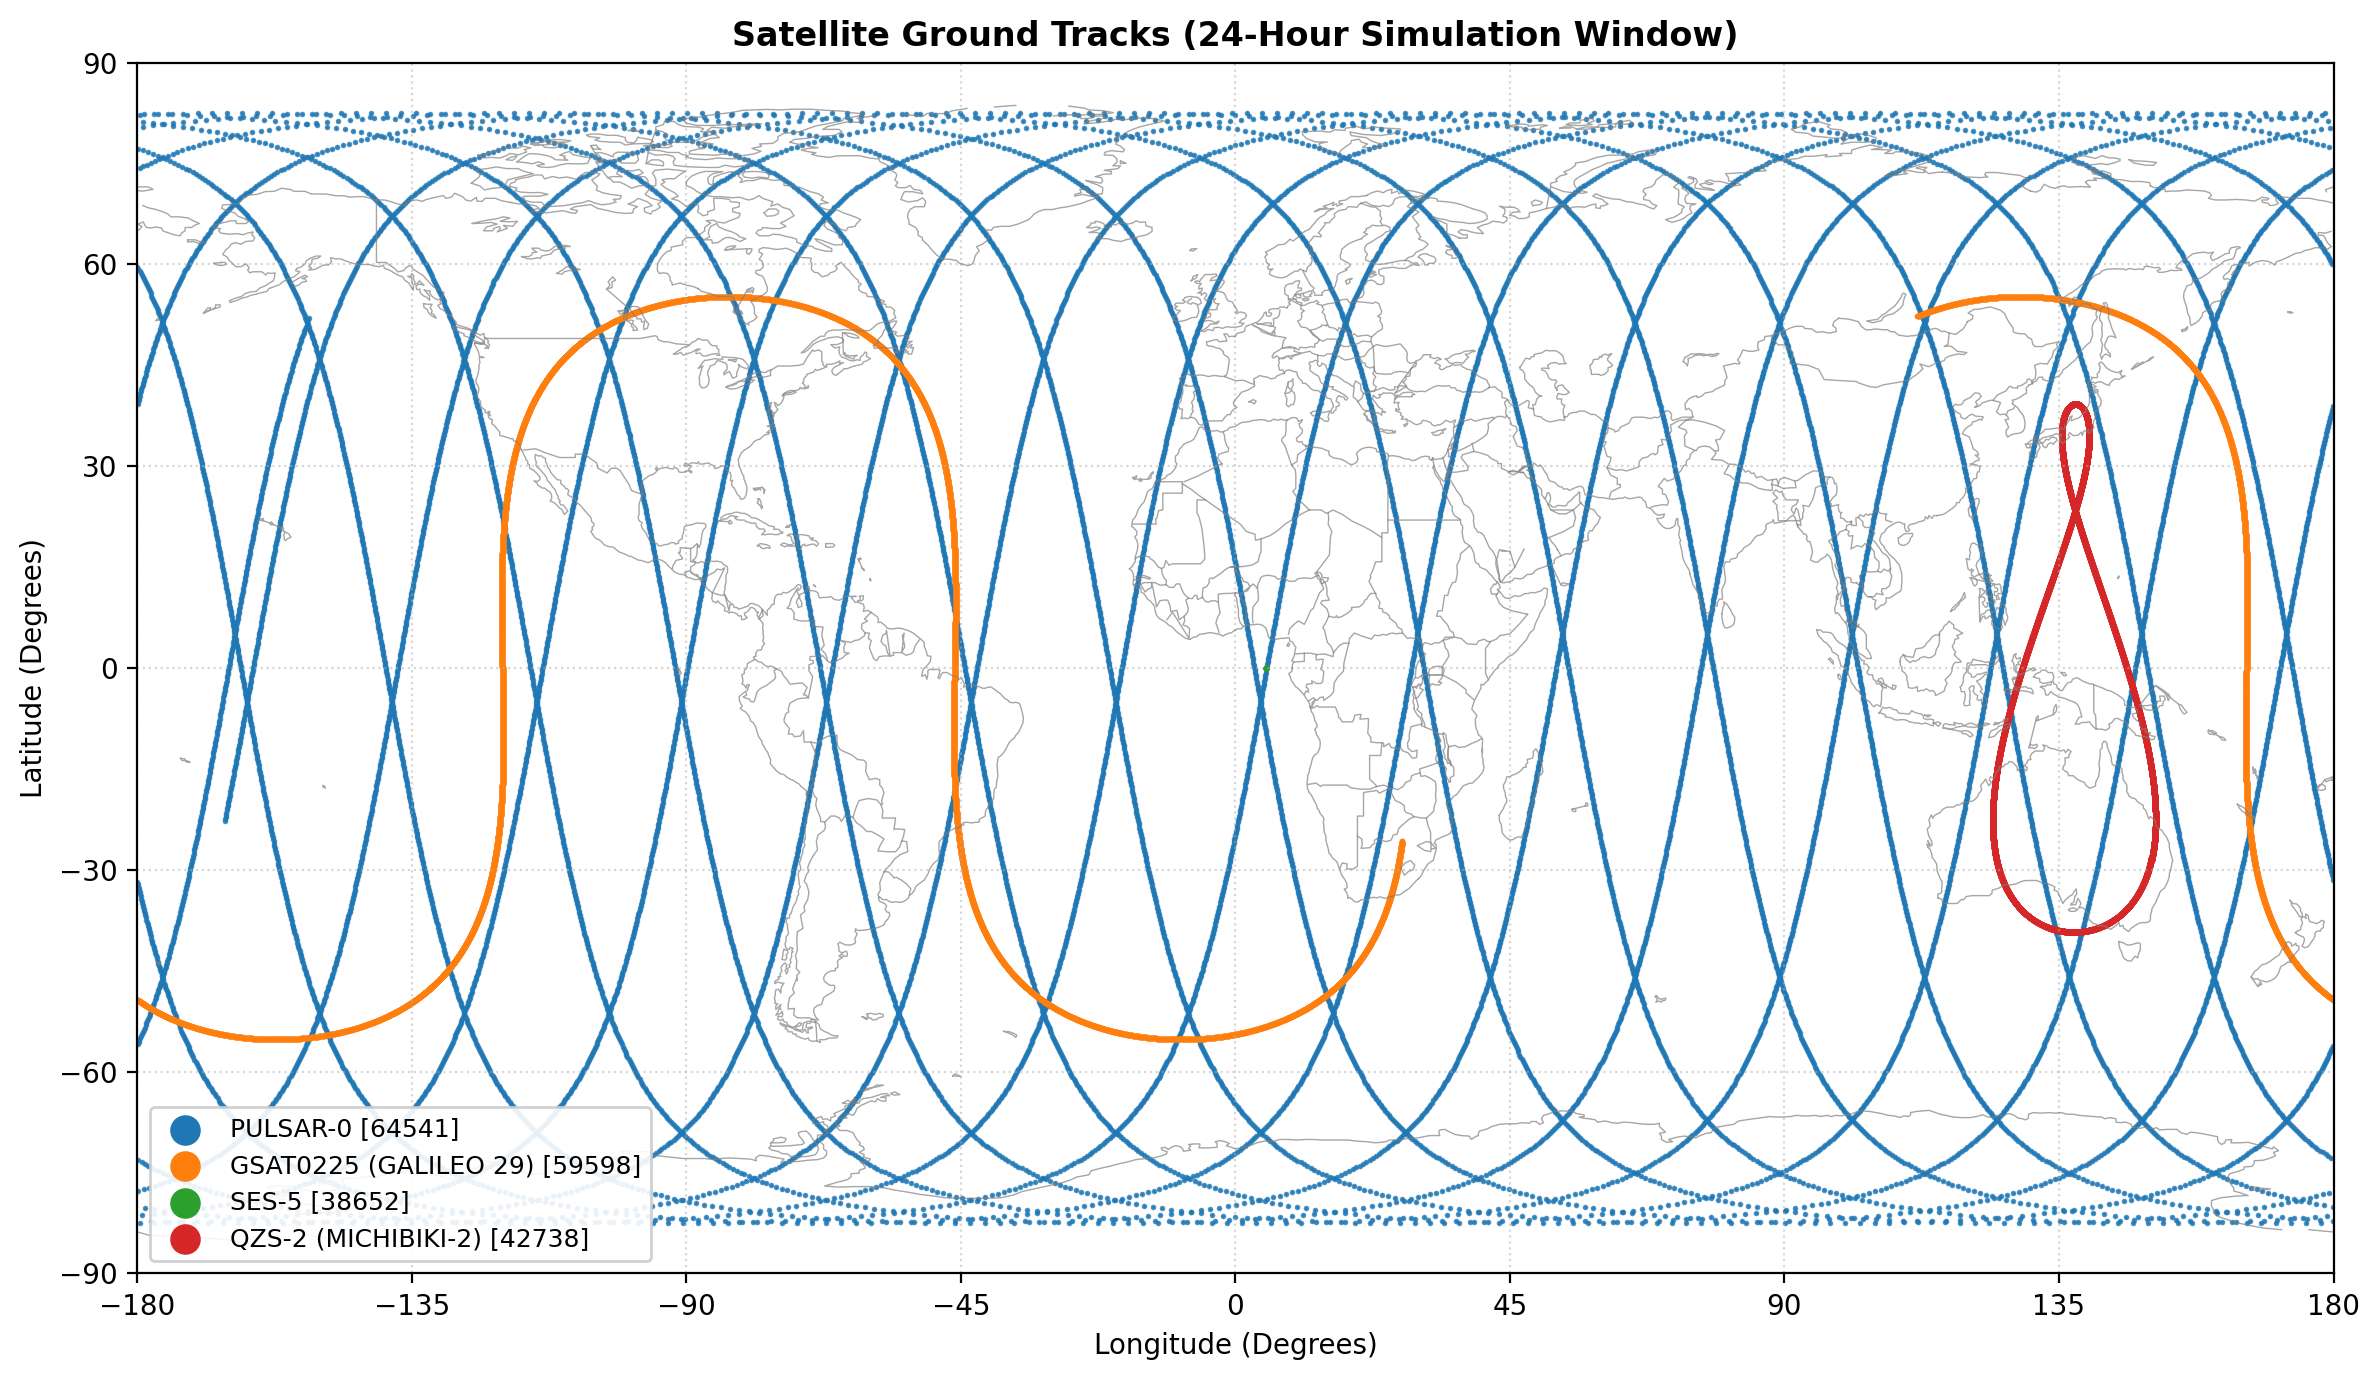

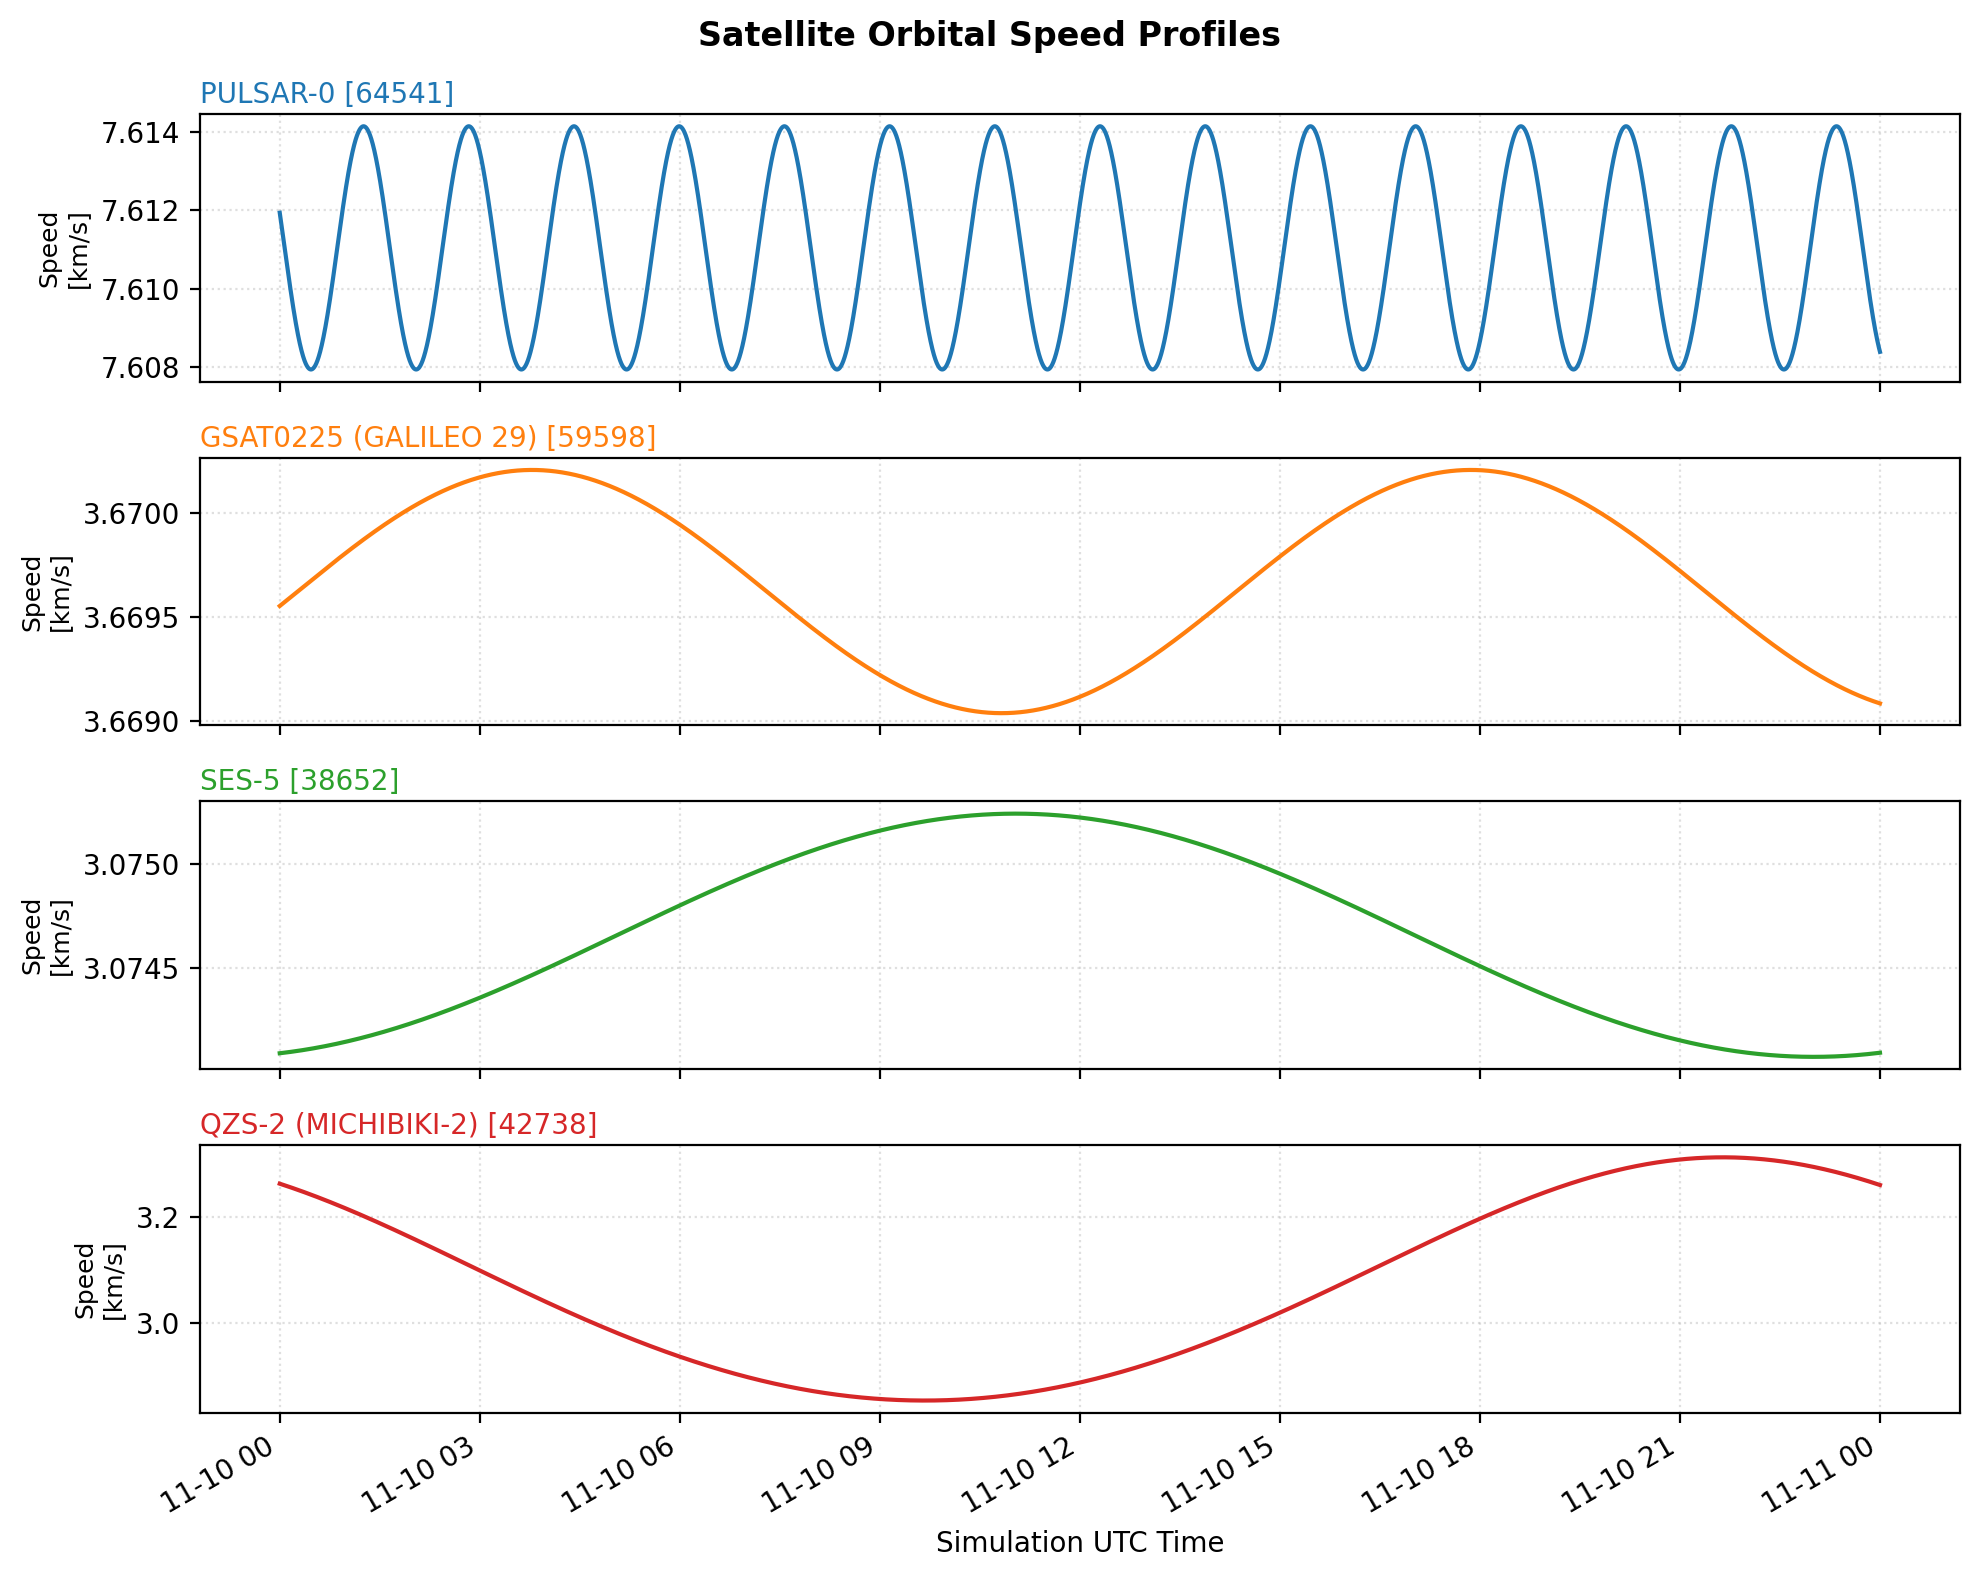


Saved visualization figures directly to /content/satellite_orbits/output:
 - ground_tracks.png
 - velocity_timeseries.png


In [25]:
# Stage 7 Implementation: Plots with Matplotlib

COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

def load_coastline(path):
    """Load world_map.txt with 'latitude longitude' (latitude FIRST) per line,
    separated by blank lines for segments. Returns a list of (lon, lat) segments.
    """
    segments = []
    current_segment = []
    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))
    if current_segment:
        segments.append(current_segment)
    return segments

# 1. Load the coastline data
coast_segments = load_coastline(IN_DIR / 'world_map.txt')

# 2. Figure 1: Ground Tracks
fig1, ax1 = plt.subplots(figsize=(12, 7), dpi=200)

# Plot coastline segments in gray
for seg in coast_segments:
    lons, lats = zip(*seg)
    ax1.plot(lons, lats, color='gray', linewidth=0.5, alpha=0.7)

# Scatter each satellite track with small dots to avoid lines crossing +/-180
for idx, (el, track) in enumerate(zip(elements, tracks)):
    color = COLORS[idx % len(COLORS)]
    lons = [pt['lon_deg'] for pt in track]
    lats = [pt['lat_deg'] for pt in track]
    ax1.scatter(lons, lats, color=color, s=1, alpha=0.8, label=el['label'])

ax1.set_title("Satellite Ground Tracks (24-Hour Simulation Window)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Longitude (Degrees)")
ax1.set_ylabel("Latitude (Degrees)")
ax1.set_xlim(-180, 180)
ax1.set_ylim(-90, 90)
ax1.set_xticks(range(-180, 181, 45))
ax1.set_yticks(range(-90, 91, 30))
ax1.grid(True, linestyle=':', alpha=0.5)

# Adjust legend handlers so dots are fully visible
leg = ax1.legend(loc='lower left', markerscale=10, fontsize=9, framealpha=0.9)
for lh in leg.legend_handles:
    lh.set_alpha(1.0)

plt.tight_layout()
fig1_path = OUT_DIR / 'ground_tracks.png'
fig1.savefig(fig1_path, dpi=200)
plt.show()

# 3. Figure 2: Speed Timeseries
fig2, axs = plt.subplots(len(elements), 1, figsize=(10, 8), sharex=True, dpi=200)
if len(elements) == 1:
    axs = [axs]

for idx, (el, track) in enumerate(zip(elements, tracks)):
    color = COLORS[idx % len(COLORS)]
    times_plot = [pt['time'] for pt in track]
    speeds = [pt['speed_km_s'] for pt in track]

    ax = axs[idx]
    ax.plot(times_plot, speeds, color=color, linewidth=1.5)
    ax.set_ylabel("Speed\n[km/s]", fontsize=9)
    ax.set_title(el['label'], fontsize=10, color=color, loc='left', pad=4)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.get_yaxis().get_major_formatter().set_useOffset(False) # No y-axis offset notation

axs[-1].set_xlabel("Simulation UTC Time")
plt.gcf().autofmt_xdate()

plt.suptitle("Satellite Orbital Speed Profiles", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig2_path = OUT_DIR / 'velocity_timeseries.png'
fig2.savefig(fig2_path, dpi=200)
plt.show()

print(f"\nSaved visualization figures directly to {OUT_DIR}:")
print(f" - {fig1_path.name}")
print(f" - {fig2_path.name}")

### Interpretation of Visualization Results

#### Ground Track Behaviors

*   **PULSAR-0 (LEO)**: Shows **many passes shifting west**. Because it is in a fast, low-Earth orbit, it circles the Earth quickly (~1.58 hours). As the satellite orbits over the poles, the Earth rotates eastward beneath it, shifting each subsequent ground track pass toward the west.
*   **GSAT0225 (Galileo 29) (MEO)**: Draws a **wide wave** across the map. This medium Earth orbit has a period of ~14.08 hours. Since its inclination is $55.2^\circ$, its ground track oscillates smoothly between $55.2^\circ$ North and South latitude, forming a wide, symmetric wave.
*   **SES-5 (GEO)**: Appears as **one dot** on the equator (at exactly $5.0^\circ$ East longitude). Because its orbital period matches the Earth's sidereal rotation period exactly (~23.93 hours) and its inclination is virtually zero, it remains stationary relative to the Earth's surface.
*   **QZS-2 (IGSO)**: Traces an **asymmetric figure-8**. Its period also equals one sidereal day, matching the Earth's rotation. However, its inclination is $39.2^\circ$, creating a north-south movement, while its eccentricity ($e \approx 0.075$) causes it to travel slower at its high northern apogee and faster at its southern perigee. This uneven speed distribution produces the asymmetric figure-8 shape with a slower, denser dwell over the Northern Hemisphere.

#### Vis-Viva Velocity Mechanics

Eccentric orbits (like **QZS-2**) experience significant speed variations over their orbital period, speeding up near perigee. According to the **Vis-Viva equation**:

$$v = \sqrt{\mu \left(\frac{2}{r} - \frac{1}{a}\right)}$$

where $r$ is the satellite's distance from the Earth's center and $a$ is the semi-major axis. Due to the **conservation of mechanical energy**, as the satellite approaches **perigee** (its closest point), its radial distance $r$ decreases to its minimum, causing gravitational potential energy to reach its lowest point. This lost potential energy is converted entirely into kinetic energy, forcing the orbital speed $v$ to reach its maximum. Conversely, at apogee (maximum $r$), the satellite slows to its minimum speed.

### Stage 8: Google Earth KML Generation, Report Compilation & Download Package

This final stage exports our 3D physical coordinate models to industry-standard geospatial formats:

1. **Style Color Mapping**: Translates standard matplotlib hex-colors (e.g., `#1f77b4`) to the KML binary color standard `aabbggrr` (e.g., `ffb4771f` for $100\%$ opacity) and links them to style nodes.
2. **Static ECEF KML (`orbit_tracks_ecef.kml`)**: Maps the 3D orbital trajectory. Altitudes are converted from kilometers to meters, with `altitudeMode` set to `absolute`.
3. **Animated ground-track KML (`orbit_animation.kml`)**: Leverages the `gx:MultiTrack` schema. To avoid diagonal artifacts across the map grid during antimeridian crossings, the track splits into distinct segments if a successive point hops by $> 180^{\circ}$ in longitude.
4. **Structured Text Report (`orbit_report.txt`)**: Generates an audit trail containing model details, simulator step size, data epochs, and both summary tables.
5. **Deployment Zipping**: Bundles both KML plots, both Stage 7 PNG plots, and the text report into a clean ZIP archive.

In [26]:
# Stage 8 Implementation: KML Generation and Reporting

import zipfile
from matplotlib.colors import to_hex

# Register standard namespaces for KML 2.2 and Google Earth extensions
ET.register_namespace('', "http://www.opengis.net/kml/2.2")
ET.register_namespace('gx', "http://www.google.com/kml/ext/2.2")

def convert_color_to_kml(mpl_color_name):
    """Convert Matplotlib color name to KML's aabbggrr hex format."""
    hex_str = to_hex(mpl_color_name).lstrip('#') # returns rrggbb
    r, g, b = hex_str[0:2], hex_str[2:4], hex_str[4:6]
    return f"ff{b}{g}{r}" # full opacity + bgr order

# =====================================================================
# 1. Generate Static ECEF Tracks KML
# =====================================================================
kml_root = ET.Element('kml', xmlns="http://www.opengis.net/kml/2.2")
doc_el = ET.SubElement(kml_root, 'Document')
ET.SubElement(doc_el, 'name').text = "Multi-Satellite Orbits | Earth-fixed"

# Define Styles for each satellite
for idx, el in enumerate(elements):
    color_kml = convert_color_to_kml(COLORS[idx % len(COLORS)])
    style = ET.SubElement(doc_el, 'Style', id=f"style_{el['norad_id']}")

    # Line Style
    line_style = ET.SubElement(style, 'LineStyle')
    ET.SubElement(line_style, 'color').text = color_kml
    ET.SubElement(line_style, 'width').text = "3"

    # Icon Style
    icon_style = ET.SubElement(style, 'IconStyle')
    ET.SubElement(icon_style, 'color').text = color_kml
    ET.SubElement(icon_style, 'scale').text = "1.2"
    icon = ET.SubElement(icon_style, 'Icon')
    ET.SubElement(icon, 'href').text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

# Add track placemarks
for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(doc_el, 'Placemark')
    ET.SubElement(placemark, 'name').text = el['name']
    ET.SubElement(placemark, 'styleUrl').text = f"#style_{el['norad_id']}"

    line_str = ET.SubElement(placemark, 'LineString')
    ET.SubElement(line_str, 'extrude').text = "0"
    ET.SubElement(line_str, 'tessellate').text = "1"
    ET.SubElement(line_str, 'altitudeMode').text = "absolute"

    coord_strings = []
    for pt in track:
        # Altitude must be converted to METERS
        alt_meters = pt['alt_km'] * 1000.0
        coord_strings.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{alt_meters:.1f}")

    ET.SubElement(line_str, 'coordinates').text = " ".join(coord_strings)

kml_static_path = OUT_DIR / 'orbit_tracks_ecef.kml'
ET.ElementTree(kml_root).write(kml_static_path, encoding='utf-8', xml_declaration=True)

# =====================================================================
# 2. Generate Animated Ground-Tracks KML
# =====================================================================
kml_anim_root = ET.Element('kml',
                           xmlns="http://www.opengis.net/kml/2.2",
                           attribs={"xmlns:gx": "http://www.google.com/kml/ext/2.2"})

doc_anim = ET.SubElement(kml_anim_root, 'Document')
ET.SubElement(doc_anim, 'name').text = "Multi-Satellite Ground Tracks | Animation"

# Define the exact same styles
for idx, el in enumerate(elements):
    color_kml = convert_color_to_kml(COLORS[idx % len(COLORS)])
    style = ET.SubElement(doc_anim, 'Style', id=f"style_anim_{el['norad_id']}")

    line_style = ET.SubElement(style, 'LineStyle')
    ET.SubElement(line_style, 'color').text = color_kml
    ET.SubElement(line_style, 'width').text = "3"

    icon_style = ET.SubElement(style, 'IconStyle')
    ET.SubElement(icon_style, 'color').text = color_kml
    icon = ET.SubElement(icon_style, 'Icon')
    ET.SubElement(icon, 'href').text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

# Build time-interpolated ground tracks
for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(doc_anim, 'Placemark')
    ET.SubElement(placemark, 'name').text = el['name']
    ET.SubElement(placemark, 'styleUrl').text = f"#style_anim_{el['norad_id']}"

    # MultiTrack container
    multi_track = ET.SubElement(placemark, 'gx:MultiTrack')
    ET.SubElement(multi_track, 'altitudeMode').text = "clampToGround"
    ET.SubElement(multi_track, 'gx:interpolate').text = "1"

    # Sample track every 60 seconds (since STEP_SECONDS = 5s, sample every 12th point)
    sampled_track = track[::12]
    if track[-1] not in sampled_track:
        sampled_track.append(track[-1])

    # Split track into segments to avoid connecting lines stretching over +/- 180 lon
    segments = []
    current_seg = []
    for pt_idx, pt in enumerate(sampled_track):
        if current_seg:
            last_lon = current_seg[-1]['lon_deg']
            if abs(pt['lon_deg'] - last_lon) > 180.0:
                # Wrap-around boundary crossed, close current segment and start a new one
                segments.append(current_seg)
                current_seg = []
        current_seg.append(pt)
    if current_seg:
        segments.append(current_seg)

    for seg_idx, seg_pts in enumerate(segments):
        track_node = ET.SubElement(multi_track, 'gx:Track')

        # Add time tags <when>
        for pt in seg_pts:
            time_str = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')
            ET.SubElement(track_node, 'when').text = time_str

        # Add coordinates <gx:coord> 'lon lat 0'
        for pt in seg_pts:
            coord_node = ET.SubElement(track_node, 'gx:coord')
            coord_node.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

kml_anim_path = OUT_DIR / 'orbit_animation.kml'
# Write manually and inject gx prefix attributes cleanly
with open(kml_anim_path, 'wb') as f:
    ET.ElementTree(kml_anim_root).write(f, encoding='utf-8', xml_declaration=True)

# =====================================================================
# 3. Compile the Analytical Text Report
# =====================================================================
report_path = OUT_DIR / 'orbit_report.txt'
with open(report_path, 'w') as f:
    f.write("Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy\n")
    f.write("=" * 80 + "\n\n")
    f.write(f"{source_note}\n\n")
    f.write("--- SIMULATION GRID SPECIFICATION ---\n")
    f.write(f"Simulation Start (UTC): {sim_start_utc}\n")
    f.write(f"Simulation End (UTC):   {sim_end_utc}\n")
    f.write(f"Time Step Duration:     {STEP_SECONDS} seconds\n")
    f.write(f"Simulation Points:      {n_points:,}\n\n")
    f.write("--- ORBITAL PROPAGATION PHYSICS CAVEAT ---\n")
    f.write("Note: This model uses mean orbital elements with an analytical two-body Keplerian propagator.\n")
    f.write("Perturbation forces such as J2 geopotential, drag, or solar radiation pressure are omitted.\n\n")

    f.write("--- SATELLITE ORBITAL ELEMENTS (INPUT TABLE) ---\n")
    for line in elements_table(elements):
        f.write(line + "\n")
    f.write("\n\n")

    f.write("--- SIMULATION STATISTICAL RESULTS (SUMMARY TABLE) ---\n")
    for line in summary_table(summaries):
        f.write(line + "\n")

# =====================================================================
# 4. Create the Deployment ZIP Archive
# =====================================================================
zip_path = OUT_DIR / 'satellite_orbit_outputs.zip'
with zipfile.ZipFile(zip_path, 'w') as zip_file:
    # Add the outputs generated in Stage 7 and 8
    zip_file.write(OUT_DIR / 'ground_tracks.png', arcname='ground_tracks.png')
    zip_file.write(OUT_DIR / 'velocity_timeseries.png', arcname='velocity_timeseries.png')
    zip_file.write(kml_static_path, arcname='orbit_tracks_ecef.kml')
    zip_file.write(kml_anim_path, arcname='orbit_animation.kml')
    zip_file.write(report_path, arcname='orbit_report.txt')

print("=== Stage 8 Completed successfully! ===")
print(f"Created Static KML: {kml_static_path.name}")
print(f"Created Animation KML: {kml_anim_path.name}")
print(f"Created Report File: {report_path.name}")
print(f"Compressed all workspace deliverables into: {zip_path.name}")

=== Stage 8 Completed successfully! ===
Created Static KML: orbit_tracks_ecef.kml
Created Animation KML: orbit_animation.kml
Created Report File: orbit_report.txt
Compressed all workspace deliverables into: satellite_orbit_outputs.zip


In [27]:
# File downloader handler
from google.colab import files

print("Initiating download for 'satellite_orbit_outputs.zip'...")
files.download(zip_path)

Initiating download for 'satellite_orbit_outputs.zip'...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Run All Checklist & Execution Guidelines

To ensure all dependencies are computed cleanly, execute all cells sequentially from top to bottom:
1. **Stage 1 (Setup)**: Configures global parameters ($\mu, R_e$, steps).
2. **Stage 2 (Load GP JSON)**: Extracts `orbit_workshop_inputs.zip` and loads the mean orbital parameter database.
3. **Stage 3 (Parse Elements)**: Translates mean parameters to model units.
4. **Stage 4 (Time Window)**: Standardizes the start/end windows.
5. **Stage 5 (Propagate)**: Solves Kepler's Equation to trace ECEF trajectory coords.
6. **Stage 6 (Orbit Summary)**: Classifies orbits and verifies Galileo 29 bounds.
7. **Stage 7 (Plots)**: Visualizes and saves spatial/speed plots.
8. **Stage 8 (KML & Report Export)**: Packages and compiles final binary deliverables.

---

### How to Open KML Files in Google Earth Pro

Once the zip archive is downloaded, extract the KML coordinates and load them into **Google Earth Pro (Desktop)** or **Google Earth Web**:

#### 1. Visualizing the Static 3D Orbits (`orbit_tracks_ecef.kml`)
*   Open Google Earth Pro and navigate to **File > Open**, then select `orbit_tracks_ecef.kml`.
*   This file maps the literal trajectories of the orbits in 3D relative to the rotating earth frame. You can rotate and zoom to observe the altitude levels of **PULSAR-0 (LEO)** relative to **Galileo (MEO)** and **SES-5 (GEO)**.

#### 2. Playing the Temporal Ground Animation (`orbit_animation.kml`)
*   Select and open `orbit_animation.kml`.
*   Because time stamps (`<when>`) are matched to coordinates (`<gx:coord>`), a **Time Slider** interface will automatically appear in the top-left corner of the Google Earth map window.
*   Click the **Play/Pause** button on the Time Slider panel to watch the satellites actively propagate along their ground paths. You can adjust the speed of playback or loop the animation to observe the figure-8 shape of **QZS-2** or the static equatorial pin-point of **SES-5**.